<a href="https://colab.research.google.com/github/P-shettar/ML-LAB-02/blob/main/program_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset downloaded successfully!
Dataset Shape: (1627, 29)
   wage_eur  age  height_cm  weight_kg nationality_name  overall  potential  \
0    120000   22        177         69              usa       82         88   
1     56000   28        193         78              usa       78         79   
2     49000   22        175         72              usa       77         83   
3     73000   26        191         86              usa       77         82   
4     57000   22        183         84              usa       77         82   

   attacking_crossing  attacking_finishing  attacking_heading_accuracy  ...  \
0                  74                   73                          50  ...   
1                  36                   39                          85  ...   
2                  55                   48                          65  ...   
3                  14                    9                          13  ...   
4                  65                   69                          80 

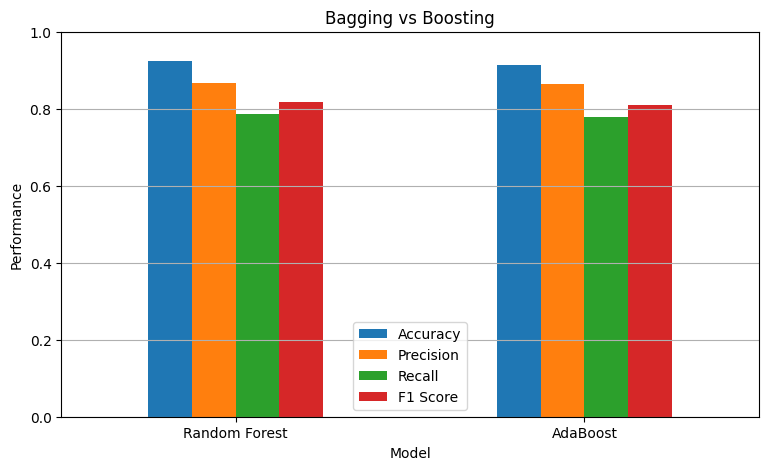

In [1]:

# EXPERIMENT 6: BAGGING AND BOOSTING

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Step 2: Download dataset
url = "https://people.stat.sc.edu/gregorkb/data/fifa_usge.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Dataset Shape:", df.shape)
print(df.head())

# Step 3: Select features
features = [
    "age", "height_cm", "weight_kg",
    "potential", "attacking_crossing",
    "attacking_finishing",
    "attacking_heading_accuracy",
    "attacking_short_passing",
    "skill_dribbling",
    "skill_ball_control",
    "movement_acceleration",
    "movement_sprint_speed",
    "movement_agility",
    "movement_reactions",
    "defending_standing_tackle",
    "defending_sliding_tackle"
]

# Keep available columns
features = [f for f in features if f in df.columns]

# Remove missing values
df = df.dropna(subset=features + ["overall"])

X = df[features]

# Create classification labels
y = pd.cut(
    df["overall"],
    bins=[0, 65, 80, 100],
    labels=["Average", "Good", "Excellent"],
    include_lowest=True
)

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardization for AdaBoost
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

# Step 5: Bagging - Random Forest
bagging = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

bagging.fit(X_train, y_train)

bagging_pred = bagging.predict(X_test)

# Step 6: Boosting - AdaBoost
boosting = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

boosting.fit(X_train_scaled, y_train)

boosting_pred = boosting.predict(X_test_scaled)

# Step 7: Evaluation function
def evaluate_model(name, actual, predicted):

    print("\n", name)
    print("-" * 40)

    print("Accuracy:",
          accuracy_score(actual, predicted))

    print("Precision:",
          precision_score(actual, predicted, average="macro"))

    print("Recall:",
          recall_score(actual, predicted, average="macro"))

    print("F1 Score:",
          f1_score(actual, predicted, average="macro"))

    print("\nConfusion Matrix:")
    print(confusion_matrix(actual, predicted))

    print("\nClassification Report:")
    print(classification_report(actual, predicted))

# Evaluate both models
evaluate_model("BAGGING - RANDOM FOREST", y_test, bagging_pred)

evaluate_model("BOOSTING - ADABOOST", y_test, boosting_pred)

# Step 8: Compare models
results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost"],
    "Accuracy": [
        accuracy_score(y_test, bagging_pred),
        accuracy_score(y_test, boosting_pred)
    ],
    "Precision": [
        precision_score(y_test, bagging_pred, average="macro"),
        precision_score(y_test, boosting_pred, average="macro")
    ],
    "Recall": [
        recall_score(y_test, bagging_pred, average="macro"),
        recall_score(y_test, boosting_pred, average="macro")
    ],
    "F1 Score": [
        f1_score(y_test, bagging_pred, average="macro"),
        f1_score(y_test, boosting_pred, average="macro")
    ]
})

print("\nFINAL COMPARISON")
print(results.to_string(index=False))

# Step 9: Plot graph
results.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1)
)

plt.title("Bagging vs Boosting")
plt.ylabel("Performance")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()
